In [1]:
library(tidyverse)
library(GenomicRanges)
library(gridExtra)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:lubridate’:

    intersect, setdiff, union


The following objects are masked from ‘package:dplyr’:

    combine, intersect, setdiff, union


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, 

In [ ]:
sessionInfo()

In [2]:
theme_set(theme_bw() + theme(rect=element_rect(linewidth=1), text=element_text(size=15), panel.grid=element_blank()))

In [3]:
bed_to_gr <- function(filename){
    temp <- read.delim(filename, header=F, sep='\t')
    gr <- GRanges(seqnames=temp$V1, ranges=IRanges(start=temp$V2, end=temp$V3))
    return(gr)
}

In [4]:
#making GR for ATAC-seq peaks

#without peak resizing
dmso_rep <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/consensus/dmso_replicated.bed")
brm_rep <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/consensus/brm014_replicated.bed")
consensus <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/consensus/consensus_peaks_sort_indexed.bed")

#with peak resizing
dmso_rep_500bp <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/consensus/dmso_replicated_summit500.bed")
brm_rep_500bp <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/consensus/brm014_replicated_summit500.bed")
consensus_500bp <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/consensus/consensus_peaks_summit500.bed")

In [7]:
#making GR from TSS, histone mod & CTCF peaks
TSS <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/GENCODE/gencode.v47.annotation.transcripts_tss.1kb.bed")
H3K4me3 <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ENCODE_cRE_definition/GM12878/H3K4me3.bed")
H3K4me1 <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ENCODE_cRE_definition/GM12878/H3K4me1.bed")
H3K27ac <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ENCODE_cRE_definition/GM12878/H3K27ac.bed")
H3K27me3 <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ENCODE_cRE_definition/GM12878/H3K27me3.bed")
CTCF <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ENCODE_cRE_definition/GM12878/CTCF.bed")

In [8]:
#defining cRE types based on TSS, histone mod, and CTCF overlaps

#which peaks overlap with TSS or other chromatin features
consensus$TSS <- ifelse(countOverlaps(consensus,TSS)>0, TRUE, FALSE)
consensus$H3K4me3 <- ifelse(countOverlaps(consensus,H3K4me3)>0, TRUE, FALSE)
consensus$H3K4me1 <- ifelse(countOverlaps(consensus,H3K4me1)>0, TRUE, FALSE)
consensus$H3K27ac <- ifelse(countOverlaps(consensus,H3K27ac)>0, TRUE, FALSE)
consensus$H3K27me3 <- ifelse(countOverlaps(consensus,H3K27me3)>0, TRUE, FALSE)
consensus$CTCF <- ifelse(countOverlaps(consensus,CTCF)>0, TRUE, FALSE)

#define type based on combinations of the above
consensus$type <- case_when(
    consensus$TSS==T & consensus$H3K4me3 ==T ~ "prom", #promoter: TSS-proximal and H3K4me3 overlapping
    consensus$TSS==T & consensus$H3K4me3 ==F ~ "other_TSS", #all other (non-H3K4me3) TSS-proximal elements
    consensus$TSS==F & consensus$H3K4me1 ==T & consensus$H3K27ac==T ~ "active_enh", #active enhancer: TSS-distal, H3K4me1 and H3K27ac overlapping
    consensus$TSS==F & consensus$H3K4me1 ==T & consensus$H3K27ac==F & consensus$H3K27me3==F ~ "poised_enh", #poised enhancer: TSS-distal, H3K4me1+ and H3K27 unmodified
    consensus$TSS==F & consensus$H3K4me1 ==T & consensus$H3K27ac==F & consensus$H3K27me3==T ~ "poised_enh_H3K27me3", #'poised' enhancers that are H3K27me3+
    consensus$TSS==F & consensus$H3K4me1 ==F & consensus$CTCF==T ~ "CTCF_only", #TSS-distal, H3K4me1- elements with CTCF binding
    consensus$TSS==F & consensus$H3K4me1 ==F & consensus$CTCF==F ~ "other_nonTSS") #all other TSS-distal, H3K4me1- elements




Warning message in .merge_two_Seqinfo_objects(x, y):
“Each of the 2 combined objects has sequence levels not in the other:
  - in 'x': chrY
  - in 'y': chr17_GL000205v2_random, chrEBV, chrUn_GL000219v1, chrUn_GL000220v1
  Make sure to always combine/compare objects based on the same reference
  genome (use suppressWarnings() to suppress this warning).”
Warning message in .merge_two_Seqinfo_objects(x, y):
“Each of the 2 combined objects has sequence levels not in the other:
  - in 'x': chrY
  - in 'y': chr17_GL000205v2_random, chrUn_GL000195v1, chrUn_GL000219v1
  Make sure to always combine/compare objects based on the same reference
  genome (use suppressWarnings() to suppress this warning).”
Warning message in .merge_two_Seqinfo_objects(x, y):
“Each of the 2 combined objects has sequence levels not in the other:
  - in 'x': chrY
  - in 'y': chr1_KI270713v1_random
  Make sure to always combine/compare objects based on the same reference
  genome (use suppressWarnings() to suppress this

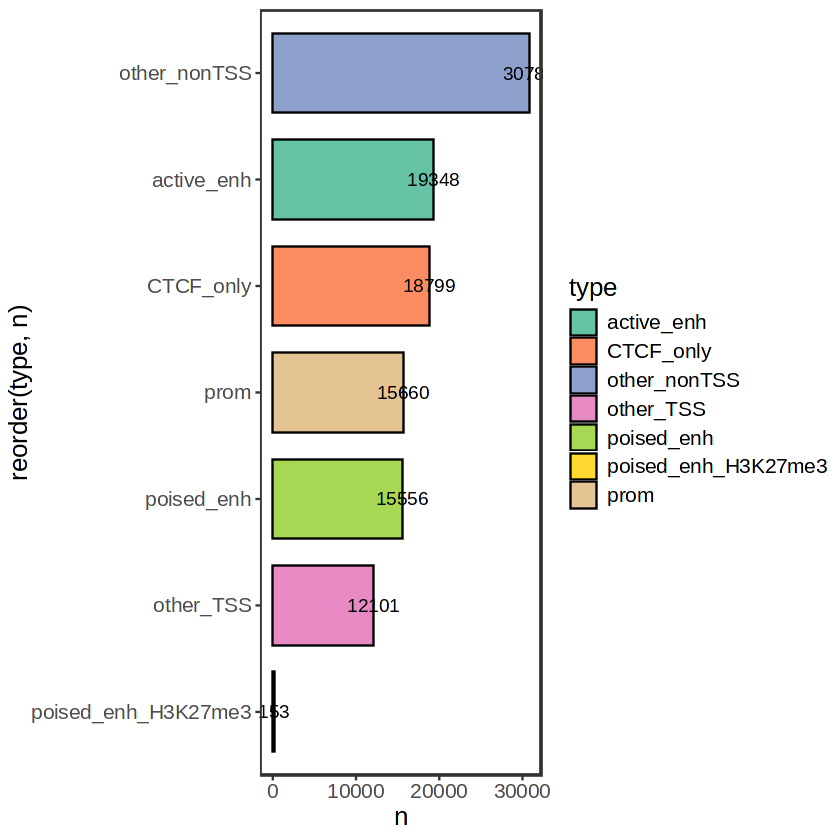

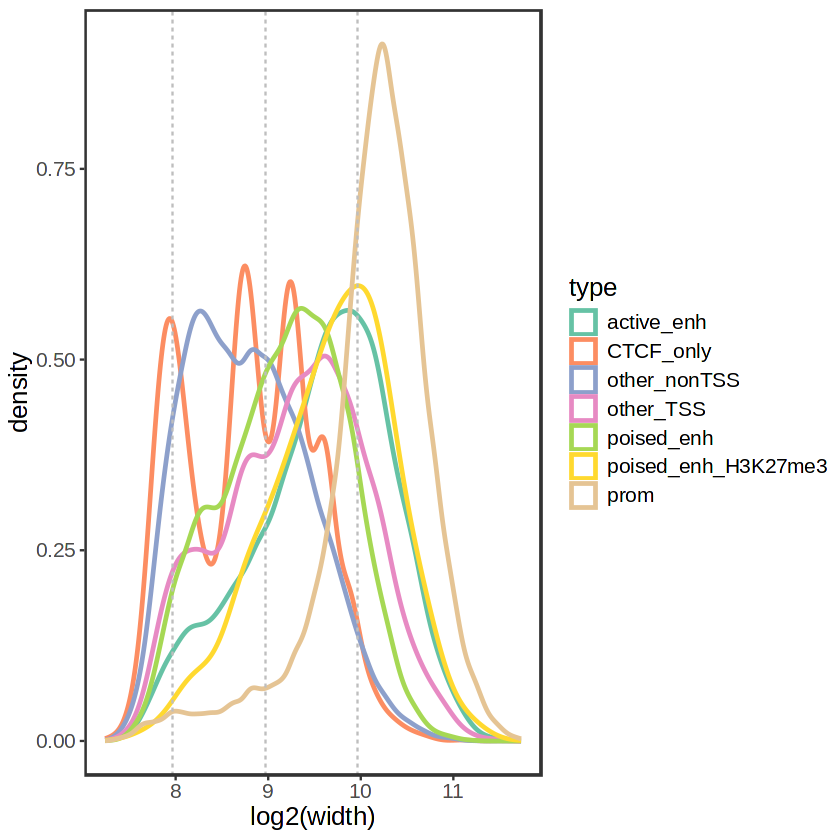

In [19]:
#look at # of cREs by type
consensus %>% data.frame() %>% group_by(type) %>% summarize(n = n()) %>% 
    ggplot(aes(y=reorder(type,n),x=n, fill=type)) + geom_col(color="black", width=.75) + geom_text(aes(label=n)) + 
    scale_fill_brewer(palette="Set2")

consensus %>% data.frame()  %>% 
    ggplot(aes(x=log2(width), color=type)) + geom_density(linewidth=1) + 
    geom_vline(xintercept=log2(c(250, 500, 1000)), linetype=2, color="grey") + 
    scale_color_brewer(palette="Set2")

In [16]:
#read in counts matrix
cm <- read.delim("~/projects/poised_enh_manuscript/inputs/countmat/brm10uM_6h/consensus_peaks_sort_indexed_counts.tsv", sep='\t', header=F)
cm <- cm %>% mutate(inDMSO=ifelse(countOverlaps(consensus,dmso_rep)>0, TRUE, FALSE), 
                    inBRM=ifelse(countOverlaps(consensus,brm_rep)>0, TRUE, FALSE),
                    dmso_avg=rowMeans(cm[,5:7]), 
                    brm_avg=rowMeans(cm[,8:10]))

consensus_counts <- GRanges(seqnames=cm$V1, ranges=IRanges(start=cm$V2,end=cm$V3), mcols=cm[,11:14])

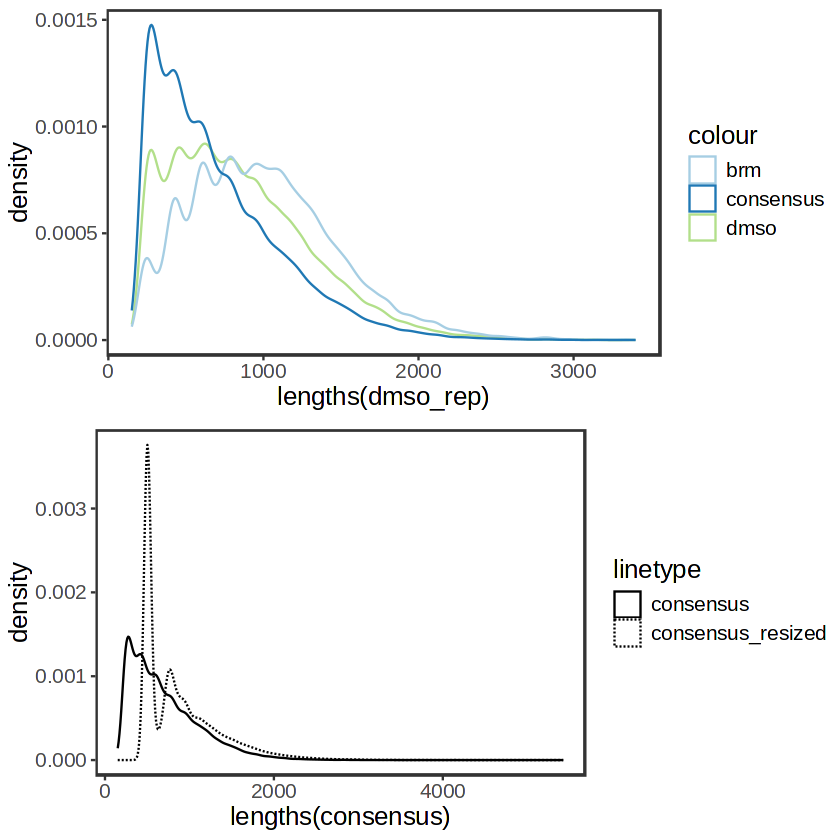

In [10]:
#Comparing peak size distributions
p1 <- ggplot() +
    geom_density(aes(color="dmso",x=lengths(dmso_rep))) +
    geom_density(aes(color="brm",x=lengths(brm_rep))) +
    geom_density(aes(color="consensus",x=lengths(consensus))) +
    scale_color_brewer(palette="Paired")

p2 <- ggplot() +
    geom_density(aes(linetype="consensus",x=lengths(consensus))) + 
    geom_density(aes(linetype="consensus_resized",x=lengths(consensus_500bp)))

grid.arrange(p1,p2,nrow=2)

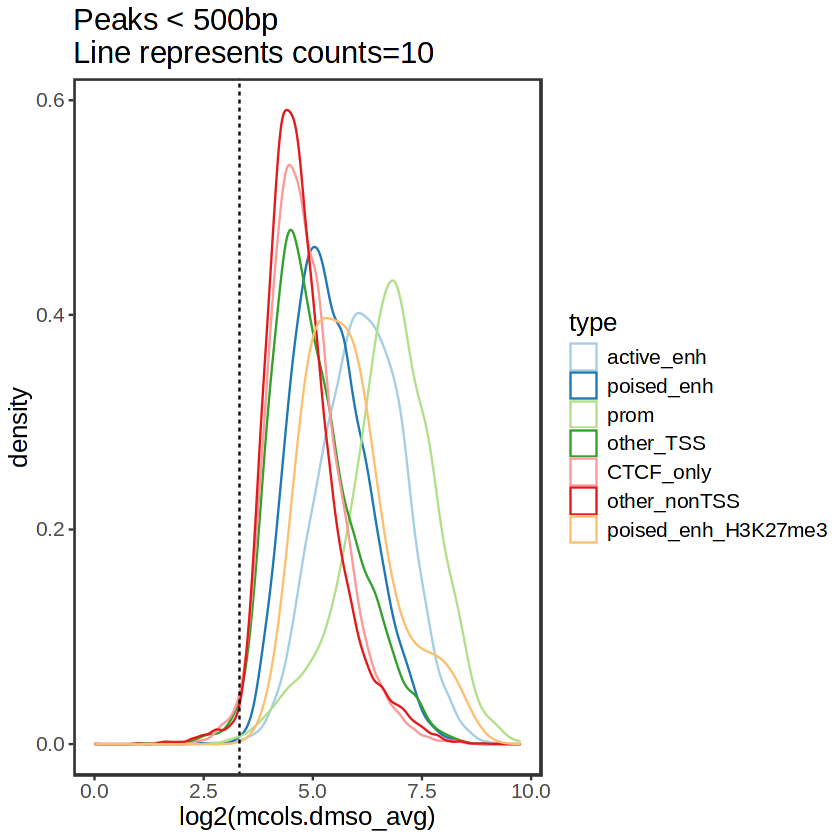

`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.
Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”
`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.


type,pct
<chr>,<dbl>
CTCF_only,1.00005319
CTCF_only,98.99994681
active_enh,0.01550548
active_enh,99.98449452
other_TSS,0.71894885
other_TSS,99.28105115
other_nonTSS,1.27976094
other_nonTSS,98.72023906
poised_enh,0.05785549


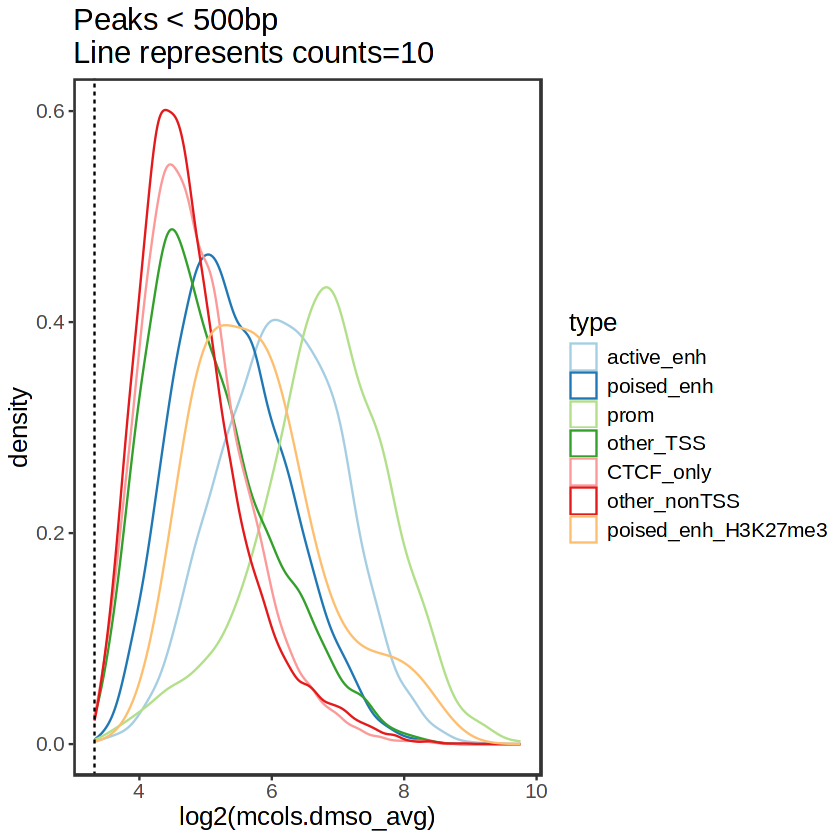

In [11]:
data.frame(consensus_counts) %>% mutate(type=consensus$type, CTCF=consensus$CTCF) %>% filter(width < 500) %>% 
    ggplot(aes(x=log2(mcols.dmso_avg), color=factor(type, levels=c("active_enh", "poised_enh", "prom", "other_TSS", "CTCF_only", "other_nonTSS", "poised_enh_H3K27me3")))) + 
    geom_density() + geom_vline(xintercept=log2(10), linetype=2) + scale_color_brewer(palette="Paired", name="type") + 
    ggtitle("Peaks < 500bp\nLine represents counts=10")

data.frame(consensus_counts) %>% mutate(type=consensus$type, CTCF=consensus$CTCF) %>% filter(width < 500, mcols.dmso_avg > 10) %>% 
    ggplot(aes(x=log2(mcols.dmso_avg), color=factor(type, levels=c("active_enh", "poised_enh", "prom", "other_TSS", "CTCF_only", "other_nonTSS", "poised_enh_H3K27me3")))) + 
    geom_density() + geom_vline(xintercept=log2(10), linetype=2) + scale_color_brewer(palette="Paired", name="type") + 
    ggtitle("Peaks < 500bp\nLine represents counts=10")

data.frame(consensus_counts) %>% mutate(type=consensus$type) %>% group_by(type, mcols.dmso_avg > 10) %>% summarize(n=n(), width=median(width), counts=median(mcols.dmso_avg)) %>% ungroup() %>% group_by(type) %>% summarize(pct=100*n/sum(n))

In [17]:
filt <- which(consensus_counts$mcols.dmso_avg <= 10)

In [18]:
consensus_filt <- data.frame(consensus, "inDMSO"=consensus_counts$mcols.inDMSO, "inBRM"=consensus_counts$mcols.inBRM)[-filt,]

In [20]:
#write out table of annotated peaks
consensus_filt <- data.frame(consensus, "inDMSO"=consensus_counts$mcols.inDMSO, "inBRM"=consensus_counts$mcols.inBRM)[-filt,] %>% mutate(ID=seq(1,nrow(consensus_filt)))
write.table(consensus_filt, "consensus_filt_annot.tsv", row.names=F, quote=F, sep='\t')
#also write out BED-formatted and indexed peak list
consensus_filt_bed <- consensus_filt %>% select(seqnames, start, end) %>% mutate(ID=seq(1,nrow(consensus_filt))) %>% `colnames<-`(NULL)
write.table(consensus_filt_bed, "consensus_filt.bed", row.names=F, quote=F, sep='\t')


.
         active_enh           CTCF_only        other_nonTSS           other_TSS 
              19345               18611               30393               12014 
         poised_enh poised_enh_H3K27me3                prom 
              15547                 153               15658 